# T22. Matrices origen–destino por franja y tipo de día

**Qué queremos ver.** Cómo cambia la demanda origen–destino por la hora local de salida y entre laborables (lunes a viernes) y fin de semana (sábado y domingo). Usamos las cinco franjas de configuración, H3 y los dos niveles administrativos de T21.

**Por qué importa.** La ocupación de una futura red depende de qué viajes salen en cada franja. La semana reservada permite comprobar por separado cuánto cambian los volúmenes y la distribución.

## 1. Matrices temporales

**Qué queremos ver.** Una matriz por división territorial, periodo, tipo de día y franja. Las franjas usan intervalos semiabiertos y se asignan según la salida en el horario de Roma.

**Por qué importa.** Las salidas y destinos aportan los mismos viajes al segmentar. El registro de T21 conserva también los extremos sin asignar, que permanecen en las matrices administrativas.

In [1]:
import h3
import numpy as np
import pandas as pd
from IPython.display import display

from comun.config import cargar_config, carpeta_tablas, ruta
from comun.datos import cargar_viajes
from comun.figuras import guardar_figura, plt
from comun.web import exportar

TEMA = "movilidad"
TABLAS = carpeta_tablas(TEMA)
cfg = cargar_config()
franjas = cfg["exploracion"]["franjas_horarias"]
res_h3 = cfg["movilidad"]["resolucion_mapas"]
TIPOS = ("laborable", "fin_de_semana")
NIVELES = ("h3", "municipio", "zona_urbanistica")
DIMENSIONES = ["periodo", "tipo_dia", "franja"]
horas = {hora: franja for franja, (inicio, fin) in franjas.items() for hora in range(inicio, fin)}
assert set(horas) == set(range(24)) and sum(fin - inicio for inicio, fin in franjas.values()) == 24

viajes = cargar_viajes()
archivo = ruta("viajes_limpios").with_name("T21_viajes_zonificados.parquet")
administrativas = [f"{nivel}_{extremo}" for nivel in NIVELES[1:] for extremo in ("o", "d")]
viajes = viajes.merge(pd.read_parquet(archivo, columns=["trip_id", *administrativas]), on="trip_id",
                      how="left", validate="one_to_one")
if viajes[administrativas].isna().any().any():
    raise ValueError("Faltan códigos de viajes en T21. Regenera la zonificación antes de ejecutar T22.")

salidas = viajes["tsO"].dt.tz_convert(cfg["datos"]["zona_horaria"])
viajes["franja"] = salidas.dt.hour.map(horas)
viajes["tipo_dia"] = np.where(salidas.dt.dayofweek < 5, TIPOS[0], TIPOS[1])
for lado in ("O", "D"):
    viajes[f"h3_{lado.lower()}"] = [
        h3.latlng_to_cell(lat, lon, res_h3)
        for lat, lon in zip(viajes[f"lat{lado}"], viajes[f"lon{lado}"])
    ]

resultados = []
for nivel in NIVELES:
    muestra = viajes.rename(columns={f"{nivel}_o": "origen", f"{nivel}_d": "destino"})
    claves = [*DIMENSIONES, "origen", "destino"]
    especificas = muestra.groupby(claves, sort=True).size().rename("viajes").reset_index()
    mes = especificas.groupby(claves[1:], as_index=False)["viajes"].sum().assign(periodo="mes")
    resultados.extend([especificas.assign(nivel=nivel), mes.assign(nivel=nivel)])

matrices = pd.concat(resultados, ignore_index=True)
matrices = matrices[["nivel", *DIMENSIONES, "origen", "destino", "viajes"]]
matrices.to_csv(TABLAS / "T22_matrices.csv", index=False, lineterminator="\n")
display(matrices.groupby(["periodo", "nivel"])["viajes"].sum().unstack())

C:\Users\Javier\AppData\Local\Temp\ipykernel_61628\495571067.py:32: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  viajes["tipo_dia"] = np.where(salidas.dt.dayofweek < 5, TIPOS[0], TIPOS[1])


nivel,h3,municipio,zona_urbanistica
periodo,,,
ajuste,16756,16756,16756
mes,23370,23370,23370
reservada,6614,6614,6614


**Conclusiones.** Las matrices se guardan en formato largo. Cada fila es un par ordenado con viajes y las combinaciones ausentes representan ceros. La suma del ajuste y la semana reservada da el mes. La salida de T23 usa estos recuentos.

## 2. Comparación de franjas y exportación

**Qué queremos ver.** Viajes al día en cada franja y proporción de las salidas del mismo tipo de día. El denominador cuenta todos los días de calendario de ese tipo en cada periodo.

**Por qué importa.** Hay más laborables que días de fin de semana, y sus recuentos absolutos responden a periodos de exposición distintos. En la web se mantiene la misma selección de zonas al cambiar de corte temporal.

C:\Users\Javier\AppData\Local\Temp\ipykernel_61628\1115562789.py:11: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  dias = (calendario.dayofweek < 5) if tipo == "laborable" else (calendario.dayofweek >= 5)
C:\Users\Javier\AppData\Local\Temp\ipykernel_61628\1115562789.py:11: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  dias = (calendario.dayofweek < 5) if tipo == "laborable" else (calendario.dayofweek >= 5)
C:\Users\Javier\AppData\Local\Temp\ipykernel_61628\1115562789.py:11: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  dias = (calendario.dayofweek < 5) if tipo == "laborable" else (calendario.dayofweek >= 5)
C:\Users\Javier\AppData\Local\Temp\ipykernel_61628\1115562789.py:11: Pandas4Warning: DatetimeIndex.dayofweek is dep

,periodo,tipo_dia,franja,horas,dias,viajes,viajes_dia,cuota_pct
0,ajuste,laborable,madrugada,0–7,15,115,7.6667,0.9587
1,ajuste,laborable,punta_manana,7–10,15,1721,114.7333,14.3476
2,ajuste,laborable,mediodia,10–16,15,4219,281.2667,35.1730
3,ajuste,laborable,punta_tarde,16–20,15,4562,304.1333,38.0325
4,ajuste,laborable,noche,20–24,15,1378,91.8667,11.4881
5,ajuste,fin_de_semana,madrugada,0–7,6,36,6.0000,0.7561
6,ajuste,fin_de_semana,punta_manana,7–10,6,207,34.5000,4.3478
7,ajuste,fin_de_semana,mediodia,10–16,6,1779,296.5000,37.3661
8,ajuste,fin_de_semana,punta_tarde,16–20,6,2058,343.0000,43.2262
9,ajuste,fin_de_semana,noche,20–24,6,681,113.5000,14.3037


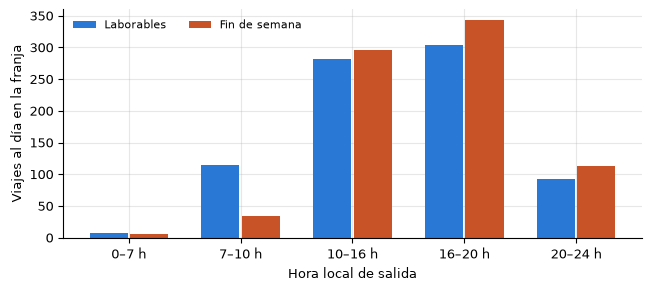

In [2]:
fechas = {
    periodo: pd.date_range(inicio, fin)
    for periodo, (inicio, fin) in cfg["datos"]["periodos"].items()
}
fechas["mes"] = fechas["ajuste"].union(fechas["reservada"])
cuentas = matrices.groupby(["nivel", *DIMENSIONES])["viajes"].sum()
segmentos = []
for periodo, calendario in fechas.items():
    muestra = viajes if periodo == "mes" else viajes.loc[viajes["periodo"].eq(periodo)]
    for tipo in TIPOS:
        dias = (calendario.dayofweek < 5) if tipo == "laborable" else (calendario.dayofweek >= 5)
        salidas_tipo = muestra.loc[muestra["tipo_dia"].eq(tipo)]
        for franja, (inicio, fin) in franjas.items():
            n = int(salidas_tipo["franja"].eq(franja).sum())
            assert all(cuentas.get((nivel, periodo, tipo, franja), 0) == n for nivel in NIVELES)
            segmentos.append({
                "periodo": periodo, "tipo_dia": tipo, "franja": franja,
                "horas": f"{inicio}–{fin}", "dias": int(dias.sum()), "viajes": n,
                "viajes_dia": n / dias.sum() if dias.any() else np.nan,
                "cuota_pct": 100 * n / len(salidas_tipo) if len(salidas_tipo) else np.nan,
            })
segmentos = pd.DataFrame(segmentos).round({"viajes_dia": 4, "cuota_pct": 4})
segmentos.to_csv(TABLAS / "T22_segmentos.csv", index=False, lineterminator="\n")
display(segmentos.loc[segmentos["periodo"].eq("ajuste")])

ajuste = segmentos.loc[segmentos["periodo"].eq("ajuste")]
fig, ax = plt.subplots(figsize=(6.4, 2.8), layout="constrained")
centros = np.arange(len(franjas))
for tipo, desfase, etiqueta, color in (
    ("laborable", -0.18, "Laborables", "#2a78d6"),
    ("fin_de_semana", 0.18, "Fin de semana", "#c85327"),
):
    ax.bar(centros + desfase, ajuste.loc[ajuste["tipo_dia"].eq(tipo), "viajes_dia"],
           width=0.34, label=etiqueta, color=color)
ax.set_xticks(centros, [f"{ini}–{fin} h" for ini, fin in franjas.values()])
ax.set_ylabel("Viajes al día en la franja")
ax.set_xlabel("Hora local de salida")
ax.set_axisbelow(True)
ax.legend(frameon=False, ncols=2)
guardar_figura(fig, TEMA, "T22_demanda_franjas")

catalogo = pd.read_csv(TABLAS / "T21_zonas.csv", dtype={"codigo": str})
niveles_web = {}
for nivel in NIVELES:
    od = matrices.loc[matrices["nivel"].eq(nivel)]
    base = od.loc[od["periodo"].eq("ajuste")]
    extremos = base.groupby("origen")["viajes"].sum().add(
        base.groupby("destino")["viajes"].sum(), fill_value=0
    ).drop(index="SIN_ASIGNAR", errors="ignore")
    if nivel == "municipio":
        zonas = catalogo.loc[catalogo["nivel"].eq(nivel), ["codigo", "nombre", "etiqueta"]]
    else:
        primeros = extremos.sort_index().nlargest(20).index
        if nivel == "h3":
            zonas = pd.DataFrame({
                "codigo": primeros, "nombre": primeros,
                "etiqueta": [str(i) for i in range(1, len(primeros) + 1)],
            })
        else:
            nivel_catalogo = catalogo.loc[catalogo["nivel"].eq(nivel)].set_index("codigo")
            zonas = nivel_catalogo.loc[primeros, ["nombre", "etiqueta"]].reset_index()

    codigos = zonas["codigo"].tolist()
    agrupado = {clave: grupo for clave, grupo in od.groupby(DIMENSIONES, sort=False)}
    cortes = {}
    for periodo, tipo, franja in segmentos[DIMENSIONES].itertuples(index=False, name=None):
        grupo = agrupado.get((periodo, tipo, franja), od.iloc[0:0])
        matriz = grupo.pivot(index="origen", columns="destino", values="viajes")
        matriz = matriz.reindex(index=codigos, columns=codigos).fillna(0).astype(int)
        cortes.setdefault(periodo, {}).setdefault(tipo, {})[franja] = matriz.to_numpy()
    niveles_web[nivel] = {"zonas": zonas, "cortes": cortes}

exportar("fase1", "t22_od_temporal", {
    "franjas": list(franjas),
    "niveles": niveles_web,
    "segmentos": segmentos,
})

**Conclusiones.** Las cifras por día permiten comparar laborables y fines de semana, y las cuotas muestran cómo se reparte la demanda dentro de cada tipo. Estas diferencias orientan la simulación por franjas. Los recortes de la web usan los municipios o las veinte zonas o celdas con más extremos en el ajuste. Los resultados completos quedan en el CSV.